# Linear probe vs full fine-tuning vs LoRA: one controlled experiment

**Why this notebook exists.** [Notebook 4](4-create-a-bert-sentiment-classifier.ipynb) trained a head on a frozen DistilBERT and got about 80% on IMDB. [Notebook 4.1](4.1-full-fine-tuning-bert.ipynb) fine-tuned every weight and got about 99% on SMS spam. It is tempting to read those two numbers as "fine-tuning is better than freezing", and that reading is wrong, because the two runs differ in dataset, class balance, sequence length, learning rate, number of epochs and amount of training data. Nothing can be concluded from comparing them. Notebook 4.1 even contained a counter-example: on spam, a frozen linear probe did at least as well as full fine-tuning.

So here I hold everything fixed except the one thing I want to study: **which parameters are allowed to move.** Same data, same test set, same number of epochs, several random seeds.

**The five regimes**, ordered by how much of the model is trained:

| # | Regime | Trained parameters | Where it comes from |
|---|---|---:|---|
| A | Off-the-shelf SST-2 model, no training | 0 | [2.2](2.2-sentimentAnalysis-transfromer.ipynb) and [3](3-pytorch-and-hugging-face-scavenger-huntscavenger-hunt.ipynb) |
| B | Linear probe on cached frozen features | 769 | [4, section 9](4-create-a-bert-sentiment-classifier.ipynb) |
| C | Frozen backbone, trained MLP head | 592,130 | [4](4-create-a-bert-sentiment-classifier.ipynb), and [3.1](3.1-transfer-learning-using-mobilenetv3.ipynb) for vision |
| D | LoRA adapters + head | 739,586 | New here, written from scratch |
| E | Full fine-tuning | 66,955,010 | [4.1](4.1-full-fine-tuning-bert.ipynb) |

**How this ties the repo together.**

| Notebook | Idea it introduced | Role in this experiment |
|---|---|---|
| [1 - Generating one token at a time](1-generating-one-token-at-a-time.ipynb) | Logits and softmax; a causal decoder | The encoder here uses the same attention without the causal mask |
| [2](2-classification-of-handwritten-digits-using-an-mlp.ipynb), [2.1](2.1-MultiLayerPerceptron.ipynb) | MLPs, loss, backprop by hand | Regime C's head is that MLP |
| [2.2](2.2-sentimentAnalysis-transfromer.ipynb), [3](3-pytorch-and-hugging-face-scavenger-huntscavenger-hunt.ipynb) | Using a model someone else fine-tuned; the PyTorch training loop | Regime A; and the loop below is the one from notebook 3 |
| [3.1 - Transfer learning](3.1-transfer-learning-using-mobilenetv3.ipynb) | Freeze a backbone, train a head (vision) | Regime C is the same recipe for text |
| [4](4-create-a-bert-sentiment-classifier.ipynb) | What a classifier is; probes; frozen DistilBERT | Regimes B and C |
| [4.1](4.1-full-fine-tuning-bert.ipynb) | Full fine-tuning; evaluation under imbalance | Regime E |

In [1]:
import logging
import math
import time
import warnings

warnings.filterwarnings("ignore")
logging.getLogger("huggingface_hub").setLevel(logging.ERROR)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import transformers

transformers.logging.set_verbosity_error()
transformers.utils.logging.disable_progress_bar()
transformers.set_seed(0)

# One plotting style for the whole notebook
BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
INK, SECONDARY, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#fcfcfb"

plt.rcParams.update(
    {
        "figure.facecolor": SURFACE,
        "axes.facecolor": SURFACE,
        "savefig.facecolor": SURFACE,
        "figure.dpi": 110,
        "savefig.dpi": 160,
        "savefig.bbox": "tight",
        "font.size": 10,
        "axes.titlesize": 11,
        "axes.titleweight": "bold",
        "axes.titlelocation": "left",
        "axes.edgecolor": "#c3c2b7",
        "axes.labelcolor": SECONDARY,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "grid.color": GRID,
        "grid.linewidth": 0.6,
        "axes.axisbelow": True,
        "xtick.color": MUTED,
        "ytick.color": MUTED,
        "text.color": INK,
        "lines.linewidth": 2,
        "legend.frameon": False,
    }
)

device = torch.device("mps" if torch.backends.mps.is_available() else "cuda" if torch.cuda.is_available() else "cpu")
print(f"torch {torch.__version__} | transformers {transformers.__version__} | device {device}")

torch 2.14.1 | transformers 5.19.0 | device mps


## 1. One family, five constraints

All five regimes can be written the same way. Start from pre-trained weights $\theta^{(0)}$ and learn an update $\Delta\theta$:

$$\theta = \theta^{(0)} + \Delta\theta, \qquad \min_{\Delta\theta \in \mathcal{C}}\; \frac{1}{n}\sum_{i=1}^{n} -\log p_{\theta^{(0)} + \Delta\theta}(y_i \mid x_i).$$

The only difference between them is the constraint set $\mathcal{C}$, the set of updates the optimizer is allowed to make:

| Regime | Constraint on $\Delta\theta$ |
|---|---|
| A. Zero-shot | $\Delta\theta = 0$. Nothing is learned from my data. (The checkpoint itself was fine-tuned by someone else, on SST-2.) |
| B, C. Frozen backbone | $\Delta\theta_b = 0$. Only the head moves. |
| D. LoRA | $\Delta W = \frac{\alpha}{r} BA$ with $\mathrm{rank}(\Delta W) \le r$ for selected matrices, zero elsewhere in the backbone. |
| E. Full fine-tuning | $\mathcal{C} = \mathbb{R}^{|\theta|}$. Anything goes. |

Seen this way the question becomes: **how large does $\mathcal{C}$ need to be?** A larger set can fit the task better, and it costs more to train and to store, and gives the optimizer more freedom to wander away from what pre-training learned.

### 1.1 LoRA

Low-Rank Adaptation (Hu et al., 2021) rests on one hypothesis: the update a task needs is much lower-dimensional than the weight matrix it is applied to. Notebook 4.1 gave some evidence for this, since a change of about 1% in the weights was enough to reorganize the whole output space, and Aghajanyan et al. (2020) measured it directly.

For a frozen weight matrix $W_0 \in \mathbb{R}^{d_{out}\times d_{in}}$, LoRA learns two small matrices and adds their product:

$$\mathbf{h} = W_0\mathbf{x} + \frac{\alpha}{r}\,B A\,\mathbf{x}, \qquad A \in \mathbb{R}^{r \times d_{in}},\quad B \in \mathbb{R}^{d_{out}\times r},\quad r \ll \min(d_{in}, d_{out}).$$

Three properties follow directly from the algebra:

1. **Parameter count.** $W_0$ has $d_{out}\,d_{in}$ entries; the adapter has $r\,(d_{in} + d_{out})$. For a $768\times768$ attention matrix with $r = 8$ that is $12{,}288$ against $589{,}824$, about 2.1%.
2. **Training starts exactly at the pre-trained model.** $B$ is initialized to zero, so $BA = 0$ and the adapted layer is identical to the original at step 0. $A$ is initialized randomly so that $B$ receives a non-zero gradient.
3. **No inference cost.** After training, the update can be folded in: $W' = W_0 + \frac{\alpha}{r}BA$ is an ordinary matrix of the original shape. The deployed model has the same architecture and latency as the base model.

Following the paper, I adapt the query and value projections ($W_Q$, $W_V$) of every attention layer. With 6 layers that is $6 \times 2 \times 12{,}288 = 147{,}456$ adapter parameters, 0.22% of the backbone. The classification head has no pre-trained value to adapt, so it is trained in full, as in every other regime.

In [2]:
class LoRALinear(nn.Module):
    """A frozen nn.Linear plus a trainable low-rank update: W0 x + (alpha / r) B A x."""

    def __init__(self, base: nn.Linear, r: int = 8, alpha: int = 16):
        super().__init__()
        self.base = base
        for p in self.base.parameters():
            p.requires_grad = False
        self.A = nn.Parameter(torch.empty(r, base.in_features))
        self.B = nn.Parameter(torch.zeros(base.out_features, r))  # zero init: start at the pre-trained model
        nn.init.kaiming_uniform_(self.A, a=math.sqrt(5))
        self.scale = alpha / r

    def forward(self, x):
        return self.base(x) + (x @ self.A.T @ self.B.T) * self.scale

    @torch.no_grad()
    def merged(self) -> nn.Linear:
        """Fold the update into a plain Linear layer for inference."""
        out = nn.Linear(self.base.in_features, self.base.out_features)
        out.weight.copy_(self.base.weight + self.scale * self.B @ self.A)
        out.bias.copy_(self.base.bias)
        return out


# Check the three properties from section 1.1 on a single 768x768 layer
base = nn.Linear(768, 768)
lora = LoRALinear(base, r=8)
x = torch.randn(4, 10, 768)

n_adapter = lora.A.numel() + lora.B.numel()
print(f"1. adapter parameters: {n_adapter:,} vs {base.weight.numel():,} in W0  ({n_adapter / base.weight.numel():.1%})")

assert torch.equal(lora(x), base(x))
print("2. at initialization the adapted layer equals the original layer exactly")

with torch.no_grad():
    lora.B.normal_(std=0.05)  # pretend training happened
assert torch.allclose(lora.merged()(x), lora(x), atol=1e-5)
print(f"3. after an update, the merged layer reproduces the adapter (rank of the update: {torch.linalg.matrix_rank(lora.B @ lora.A).item()})")

1. adapter parameters: 12,288 vs 589,824 in W0  (2.1%)
2. at initialization the adapted layer equals the original layer exactly
3. after an update, the merged layer reproduces the adapter (rank of the update: 8)


## 2. Data

IMDB again, as in notebook 4, but with 1,000 training and 1,000 test reviews so that differences between regimes are easier to see. To keep nine training runs quick on a laptop I truncate at 256 tokens instead of 512. That discards more of each long review, so absolute accuracies are a little lower than they would be at full length; it applies equally to every regime.

In [3]:
import datasets
from datasets import load_dataset
from torch.utils.data import DataLoader
from transformers import AutoModelForSequenceClassification, AutoTokenizer, DataCollatorWithPadding

datasets.disable_progress_bars()

BASE = "distilbert/distilbert-base-uncased"
MAX_LENGTH = 256

tokenizer = AutoTokenizer.from_pretrained(BASE)
collator = DataCollatorWithPadding(tokenizer=tokenizer)

raw = load_dataset("stanfordnlp/imdb")
data = {}
for split in ["train", "test"]:
    subset = raw[split].shuffle(seed=42).select(range(1000))
    data[split] = subset.map(
        lambda x: tokenizer(x["text"], truncation=True, max_length=MAX_LENGTH), batched=True
    ).remove_columns(["text"])

y_train, y_test = np.array(data["train"]["label"]), np.array(data["test"]["label"])
print(f"train: {len(y_train)} reviews, {y_train.mean():.1%} positive")
print(f"test : {len(y_test)} reviews, {y_test.mean():.1%} positive")


@torch.no_grad()
def predict_logits(model, dataset, batch_size=64):
    model.eval()
    out = []
    for batch in DataLoader(dataset, batch_size=batch_size, collate_fn=collator):
        batch = {k: v.to(device) for k, v in batch.items() if k != "labels"}
        out.append(model(**batch).logits.float().cpu())
    return torch.cat(out).numpy()


def accuracy_of(model):
    return float((predict_logits(model, data["test"]).argmax(axis=1) == y_test).mean())

train: 1000 reviews, 48.8% positive
test : 1000 reviews, 48.8% positive


## 3. The regimes that need no gradient descent

### A. Zero-shot transfer from SST-2

`distilbert-base-uncased-finetuned-sst-2-english` is the model I downloaded in notebooks 2.2 and 3. It is the same architecture, already fine-tuned for sentiment on the Stanford Sentiment Treebank: single sentences from film reviews. Applying it to IMDB is a small domain shift (full multi-paragraph reviews instead of single sentences) with zero training on my side.

### B. Linear probe

Exactly the procedure of notebook 4, section 9: run the frozen backbone once, cache one vector per review, fit logistic regression. I fit it on two different summaries of the same hidden states to follow up on a limitation I noted there:

- the `[CLS]` vector, $\mathbf{x}^{(L)}_{\texttt{[CLS]}}$
- the **mean** of all non-padding token vectors, $\frac{1}{\sum_i m_i}\sum_i m_i\,\mathbf{x}^{(L)}_i$, where $m_i$ is the attention mask

In [4]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

records = []  # one row per (regime, seed)

# --- A. zero-shot ---
sst2 = AutoModelForSequenceClassification.from_pretrained(
    "distilbert/distilbert-base-uncased-finetuned-sst-2-english"
).to(device)
start = time.perf_counter()
zero_shot_accuracy = accuracy_of(sst2)
records.append({"regime": "A. zero-shot (SST-2 model)", "seed": 0, "trainable": 0, "accuracy": zero_shot_accuracy, "train seconds": 0.0})
del sst2

# --- B. linear probes on cached features ---
backbone = AutoModelForSequenceClassification.from_pretrained(BASE, num_labels=2).distilbert.to(device).eval()


@torch.no_grad()
def cached_features(dataset, batch_size=64):
    cls, mean = [], []
    for batch in DataLoader(dataset, batch_size=batch_size, collate_fn=collator):
        batch = {k: v.to(device) for k, v in batch.items() if k != "labels"}
        hidden = backbone(**batch).last_hidden_state
        mask = batch["attention_mask"].unsqueeze(-1).float()
        cls.append(hidden[:, 0].cpu())
        mean.append(((hidden * mask).sum(1) / mask.sum(1)).cpu())
    return torch.cat(cls).numpy(), torch.cat(mean).numpy()


start = time.perf_counter()
train_cls, train_mean = cached_features(data["train"])
test_cls, test_mean = cached_features(data["test"])
feature_seconds = time.perf_counter() - start
del backbone

for name, train_x, test_x in [("B. linear probe, [CLS]", train_cls, test_cls), ("B. linear probe, mean-pooled", train_mean, test_mean)]:
    start = time.perf_counter()
    probe = make_pipeline(StandardScaler(), LogisticRegression(C=0.01, max_iter=5000)).fit(train_x, y_train)
    fit_seconds = time.perf_counter() - start
    records.append({"regime": name, "seed": 0, "trainable": 769, "accuracy": probe.score(test_x, y_test),
                    "train seconds": feature_seconds + fit_seconds})

print(f"feature extraction for 2,000 reviews: {feature_seconds:.1f}s (one forward pass each, no gradients)")
pd.DataFrame(records)[["regime", "trainable", "accuracy", "train seconds"]].round(3)

feature extraction for 2,000 reviews: 7.8s (one forward pass each, no gradients)


,regime,trainable,accuracy,train seconds
0,A. zero-shot (SST-2 model),0,0.867,0.000
1,"B. linear probe, [CLS]",769,0.831,7.801
2,"B. linear probe, mean-pooled",769,0.835,7.779


## 4. The regimes trained by gradient descent

For C, D and E I use one training loop, the same five lines as in [notebook 3](3-pytorch-and-hugging-face-scavenger-huntscavenger-hunt.ipynb): forward, loss, backward, step, zero the gradients. Writing it by hand instead of using `Trainer` makes it obvious that the three regimes differ **only** in which parameters have `requires_grad=True` and in the learning rate.

**Held fixed across regimes:** data, 3 epochs, batch size 16, AdamW with weight decay 0.01, linear schedule with 10% warm-up (the stabilizing change Mosbach et al. recommend, which the exercise notebooks did not have), and seeds 0, 1, 2.

**Varies by regime:** the learning rate. This is unavoidable. Notebook 4.1, section 5.4 explained why a randomly initialized head and a pre-trained backbone need learning rates two orders of magnitude apart. Using a single value for all three would cripple at least one of them. I take the values from the earlier notebooks and from common practice for LoRA, and I did not tune them:

| Regime | Learning rate | Source |
|---|---|---|
| C. head only | $2\times10^{-3}$ | Notebook 4 |
| D. LoRA + head | $5\times10^{-4}$ | Typical for LoRA; sits between the other two |
| E. full fine-tuning | $2\times10^{-5}$ | Notebook 4.1, BERT paper's grid |

In [5]:
from transformers import get_linear_schedule_with_warmup


def build_model(regime):
    model = AutoModelForSequenceClassification.from_pretrained(BASE, num_labels=2, attn_implementation="eager")
    if regime in ("head", "lora"):
        for p in model.distilbert.parameters():
            p.requires_grad = False
    if regime == "lora":
        for layer in model.distilbert.transformer.layer:
            layer.attention.q_lin = LoRALinear(layer.attention.q_lin, r=8, alpha=16)
            layer.attention.v_lin = LoRALinear(layer.attention.v_lin, r=8, alpha=16)
    return model


def train_and_evaluate(regime, lr, seed, epochs=3, batch_size=16):
    transformers.set_seed(seed)  # controls the head's initialization, dropout and LoRA's A matrices
    model = build_model(regime).to(device)
    params = [p for p in model.parameters() if p.requires_grad]
    optimizer = torch.optim.AdamW(params, lr=lr, weight_decay=0.01)
    loader = DataLoader(data["train"], batch_size=batch_size, shuffle=True, collate_fn=collator,
                        generator=torch.Generator().manual_seed(seed))
    total_steps = epochs * len(loader)
    scheduler = get_linear_schedule_with_warmup(optimizer, int(0.1 * total_steps), total_steps)

    train_seconds, per_epoch = 0.0, []
    for epoch in range(epochs):
        model.train()
        start = time.perf_counter()
        for batch in loader:
            batch = {k: v.to(device) for k, v in batch.items()}
            loss = model(**batch).loss   # forward + cross-entropy
            loss.backward()              # gradients for everything with requires_grad=True
            optimizer.step()
            scheduler.step()
            optimizer.zero_grad()
        if device.type == "mps":
            torch.mps.synchronize()
        train_seconds += time.perf_counter() - start
        per_epoch.append(accuracy_of(model))

    result = {"trainable": sum(p.numel() for p in params), "accuracy": per_epoch[-1], "train seconds": train_seconds,
              "accuracy by epoch": per_epoch}
    del model, optimizer
    if device.type == "mps":
        torch.mps.empty_cache()
    return result


REGIMES = [
    ("C. frozen backbone, MLP head", "head", 2e-3),
    ("D. LoRA (r=8) + head", "lora", 5e-4),
    ("E. full fine-tuning", "full", 2e-5),
]
SEEDS = [0, 1, 2]

for name, regime, lr in REGIMES:
    for seed in SEEDS:
        result = train_and_evaluate(regime, lr, seed)
        records.append({"regime": name, "seed": seed, **result})
        print(f"{name:30s} seed {seed}: accuracy {result['accuracy']:.3f}  "
              f"({result['trainable']:>10,} trainable, {result['train seconds']:5.0f}s)")

C. frozen backbone, MLP head   seed 0: accuracy 0.824  (   592,130 trainable,    15s)


C. frozen backbone, MLP head   seed 1: accuracy 0.822  (   592,130 trainable,    15s)


C. frozen backbone, MLP head   seed 2: accuracy 0.830  (   592,130 trainable,    15s)


D. LoRA (r=8) + head           seed 0: accuracy 0.857  (   739,586 trainable,    31s)


D. LoRA (r=8) + head           seed 1: accuracy 0.855  (   739,586 trainable,    31s)


D. LoRA (r=8) + head           seed 2: accuracy 0.857  (   739,586 trainable,    31s)


E. full fine-tuning            seed 0: accuracy 0.851  (66,955,010 trainable,    43s)


E. full fine-tuning            seed 1: accuracy 0.859  (66,955,010 trainable,    44s)


E. full fine-tuning            seed 2: accuracy 0.861  (66,955,010 trainable,    44s)


## 5. Results

In [6]:
runs = pd.DataFrame(records)
summary = (
    runs.groupby("regime", sort=False)
    .agg(trainable=("trainable", "first"), runs=("seed", "size"), mean_accuracy=("accuracy", "mean"),
         std=("accuracy", "std"), min_accuracy=("accuracy", "min"), max_accuracy=("accuracy", "max"),
         train_seconds=("train seconds", "mean"))
)
summary["share of model"] = (summary["trainable"] / 66_955_010).map("{:.3%}".format)
summary["trainable"] = summary["trainable"].map("{:,}".format)
summary.round(3).fillna("-")

,trainable,runs,mean_accuracy,std,min_accuracy,max_accuracy,train_seconds,share of model
regime,,,,,,,,
A. zero-shot (SST-2 model),0,1,0.867,-,0.867,0.867,0.000,0.000%
"B. linear probe, [CLS]",769,1,0.831,-,0.831,0.831,7.801,0.001%
"B. linear probe, mean-pooled",769,1,0.835,-,0.835,0.835,7.779,0.001%
"C. frozen backbone, MLP head","592,130",3,0.825,0.004,0.822,0.830,14.866,0.884%
D. LoRA (r=8) + head,"739,586",3,0.856,0.001,0.855,0.857,30.800,1.105%
E. full fine-tuning,"66,955,010",3,0.857,0.005,0.851,0.861,43.813,100.000%


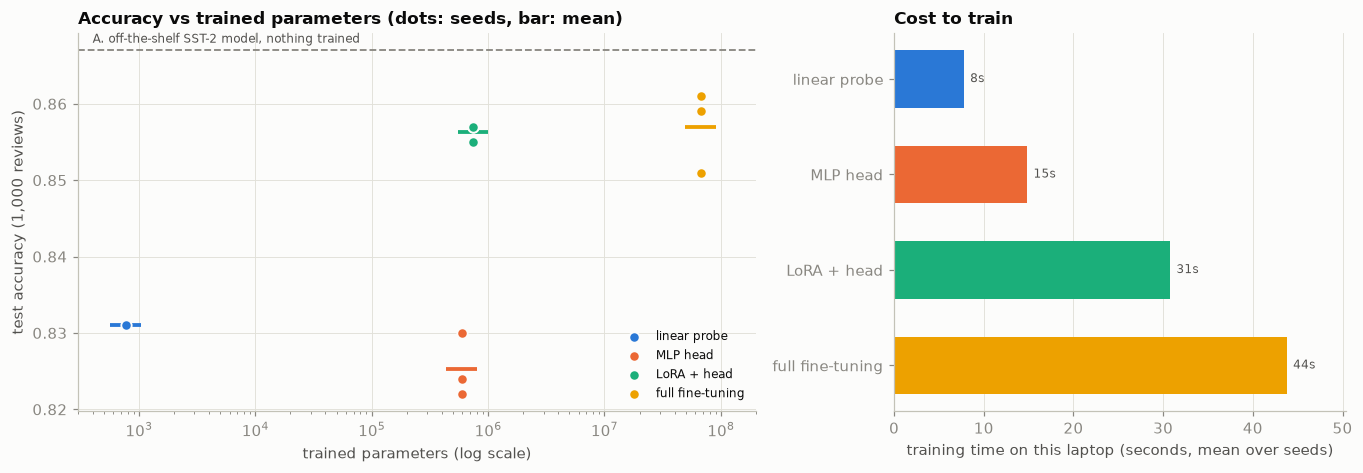

In [7]:
# Figure 1: accuracy against the number of trained parameters, and what each regime costs to train
plotted = [
    ("B. linear probe, [CLS]", BLUE, "linear probe"),
    ("C. frozen backbone, MLP head", ORANGE, "MLP head"),
    ("D. LoRA (r=8) + head", AQUA, "LoRA + head"),
    ("E. full fine-tuning", YELLOW, "full fine-tuning"),
]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.5, 4.4), gridspec_kw={"width_ratios": [1.5, 1]})

ax1.axhline(zero_shot_accuracy, color=MUTED, linestyle="--", linewidth=1.2)
ax1.annotate("A. off-the-shelf SST-2 model, nothing trained", xy=(4e2, zero_shot_accuracy), xytext=(0, 5),
             textcoords="offset points", fontsize=8, color=SECONDARY)
for regime, color, label in plotted:
    rows = runs[runs["regime"] == regime]
    x = rows["trainable"].iloc[0]
    ax1.scatter(rows["trainable"], rows["accuracy"], s=46, color=color, edgecolor=SURFACE, linewidth=1.2, zorder=3, label=label)
    ax1.hlines(rows["accuracy"].mean(), x / 1.35, x * 1.35, color=color, linewidth=2.5, zorder=2)
ax1.set_xscale("log")
ax1.set(xlabel="trained parameters (log scale)", ylabel="test accuracy (1,000 reviews)",
        title="Accuracy vs trained parameters (dots: seeds, bar: mean)", xlim=(3e2, 2e8))
ax1.legend(loc="lower right", fontsize=8)

cost = runs[runs["regime"].isin([r for r, _, _ in plotted])].groupby("regime", sort=False)["train seconds"].mean()
bars = ax2.barh([label for _, _, label in plotted][::-1], [cost[r] for r, _, _ in plotted][::-1],
                color=[c for _, c, _ in plotted][::-1], height=0.6)
for bar in bars:
    ax2.annotate(f"{bar.get_width():.0f}s", xy=(bar.get_width(), bar.get_y() + bar.get_height() / 2), xytext=(4, 0),
                 textcoords="offset points", va="center", fontsize=8, color=SECONDARY)
ax2.set(xlabel="training time on this laptop (seconds, mean over seeds)", title="Cost to train", xlim=(0, cost.max() * 1.15))
ax2.grid(axis="y", visible=False)

fig.tight_layout()
fig.savefig("assets/4.2-accuracy-vs-parameters.png")
plt.show()

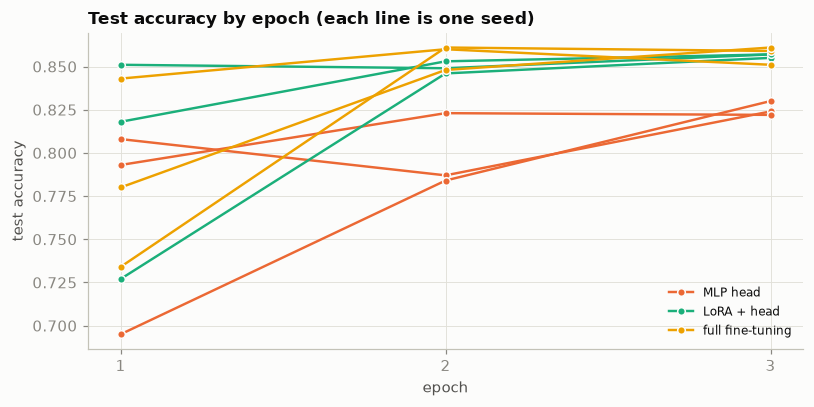

In [8]:
# Figure 2: test accuracy after each epoch, one line per seed
fig, ax = plt.subplots(figsize=(7.5, 3.8))
for regime, color, label in plotted[1:]:
    rows = runs[runs["regime"] == regime]
    for i, curve in enumerate(rows["accuracy by epoch"]):
        ax.plot([1, 2, 3], curve, color=color, marker="o", markersize=5, markeredgecolor=SURFACE, linewidth=1.6,
                label=label if i == 0 else None)
ax.set(xlabel="epoch", ylabel="test accuracy", xticks=[1, 2, 3], title="Test accuracy by epoch (each line is one seed)")
ax.legend(loc="lower right", fontsize=8)
fig.tight_layout()
fig.savefig("assets/4.2-accuracy-by-epoch.png")
plt.show()

## 6. What the experiment shows

**1. LoRA matched full fine-tuning with 1.1% of the parameters.** LoRA averaged 85.6% and full fine-tuning 85.7%. That 0.1-point gap is smaller than the spread between seeds of full fine-tuning alone (85.1% to 86.1%). On this task, restricting the update to rank 8 in two matrices per layer cost nothing measurable. It is the low-intrinsic-dimension hypothesis from section 1.1 holding up in a small experiment.

**2. Adapting the backbone is worth about 3 points; the size of the head is worth nothing.** Every LoRA and full fine-tuning run beat every frozen-backbone run, with no overlap between the groups across seeds. Within the frozen group, the 592K-parameter MLP head (82.5%) did no better than a 769-parameter logistic regression (83.1%). Going from B to C multiplies the trained parameters by 770 and changes nothing; going from C to D adds 25% more parameters and gains 3 points. **What matters is where the trainable parameters sit, not how many there are.** Parameters inside the encoder can change the representation. Parameters stacked on top of a frozen one can only re-read it.

**3. The best model was the one I did not train.** The off-the-shelf SST-2 checkpoint scored 86.7% without seeing a single IMDB review, ahead of everything I trained on 1,000 of them. It was fine-tuned on tens of thousands of labelled sentiment examples from a neighbouring domain, and that much relevant supervision beat every choice of method on my small sample. With 1,000 test reviews the 95% interval on any of these accuracies is roughly ±2 points, so I would not claim A is strictly better than D or E. The claim I am comfortable with is that **more task-relevant data, even from a slightly different distribution, was worth at least as much as the best adaptation method.** Before fine-tuning anything, check whether someone already has.

**4. Mean pooling did not help.** In notebook 4 I suggested that mean-pooled token vectors might be a better frozen feature than `[CLS]`. Here it is 83.5% against 83.1%, four reviews out of a thousand. That idea is not supported by this data.

**5. LoRA's saving is in memory and storage, not in training time.** LoRA took 31 seconds per run against 44 for full fine-tuning, about 30% less, nowhere near the 99% reduction in trained parameters. The reason is in notebook 4.1, section 5.2: to compute the gradient for an adapter in layer 1, the backward pass still has to travel through every layer above it. What LoRA does save is everything proportional to the *number of trained parameters*: optimizer state, and above all the artifact you store per task, about 3 MB of adapters and head against 268 MB for a full copy. The frozen-backbone regimes are cheaper in a different way: they need no backward pass through the encoder at all (15 seconds), and with cached features, no repeated forward pass either (8 seconds, once).

**6. Seeds matter early and less later.** After one epoch, runs of the same regime differ by up to 12 points. By epoch 3 each regime has converged to within a point. A single run stopped early can land almost anywhere, which is the instability Mosbach et al. describe, and a reminder that the single-seed numbers in notebooks 4 and 4.1 should be held loosely.

### The comparison I could not make before

| Question | Answer from this experiment |
|---|---|
| Is full fine-tuning better than a frozen backbone? | On IMDB, yes, by about 3 points. On SMS spam (4.1), no. It depends on whether the pre-trained features already separate the classes. |
| Do I need to update all the weights to get that gain? | No. A rank-8 update to 1.1% of them gets all of it. |
| Does a bigger head on a frozen backbone help? | No. |
| What should I try first? | An existing fine-tuned model, then a linear probe (seconds, and it tells you how separable the task already is), then LoRA. Full fine-tuning last. |

## 7. Why the industry cares about the middle of this spectrum

The results above are small-scale, but the economics they point to are the reason parameter-efficient methods exist.

**Storage and serving.** Full fine-tuning produces one complete model per task. Houlsby et al. (2019), at Google, framed the problem exactly this way when they introduced adapter modules: with many downstream tasks, a full copy per task is wasteful. Their adapters came within 0.4% of full fine-tuning on GLUE while adding only 3.6% parameters per task. LoRA (Hu et al., 2021, at Microsoft) pushed further: against full fine-tuning of GPT-3 175B they report **10,000 times fewer trainable parameters and 3 times less GPU memory**, with no added inference latency because the update merges into the weights (property 3 in section 1.1). The practical consequence is that one base model can stay loaded while small per-task or per-customer updates are swapped in, instead of hosting a separate multi-gigabyte model for each.

**Reusing a forward pass that is already being paid for.** The regimes at the frozen end are attractive for a different reason. Anthropic's work on cheap safety classifiers (Cunningham et al., 2025) trains linear probes on the activations of the model that is *already* answering the user, and reports performance comparable to a separate classifier 2% of the policy model's size at close to zero additional compute. That is regime B, with the backbone's forward pass costing nothing extra because it has to run anyway. They also evaluate fine-tuning only the final layer, which sits between my regimes C and D.

**Robustness, not only accuracy.** Kumar et al. (2022) show (on vision benchmarks) that full fine-tuning can *lose* to a linear probe out of distribution, because it distorts pre-trained features while fitting the training set. Averaged over ten distribution-shift datasets, fine-tuning was 2% better in-distribution and 7% worse out-of-distribution than linear probing. Their fix, LP-FT, is to train the probe first and then fine-tune from that starting point. I measured only in-distribution accuracy here, so this experiment cannot see that effect at all. It is the first thing I would add.

**The pattern.** The frozen-to-full spectrum is a cost dial, and production systems choose a point on it per use case: probes where the backbone is shared and latency is critical, low-rank adapters where many tasks share one model, full fine-tuning where a single task justifies its own copy.

## 8. Limitations, and what comes next

**What this experiment does not establish.**

- **Learning rates were not tuned.** Each regime got one plausible value. A proper comparison would sweep the learning rate per regime on a validation split and compare each at its best. It is possible the frozen head closes part of the gap with tuning, though the linear probe, which has no learning rate at all, suggests not much.
- **Three seeds, one test sample.** Seed variance is measured; test-set sampling variance (about ±2 points) is shared by all runs and is larger than most of the gaps discussed. Conclusions 1 and 2 are robust to that. The ranking of A against D and E is not.
- **One dataset, one model size, one rank.** I did not vary $r$, the choice of adapted matrices, or the amount of training data. The gap between regimes is known to depend on all three, and in particular to widen with more data.
- **In-distribution only.** See the note on Kumar et al. above.
- **256-token truncation** to make the runs affordable.

**Where the repo goes from here.**

1. **LP-FT**: initialize full fine-tuning from the trained probe, and evaluate both in-distribution (IMDB) and out-of-distribution (for example SST-2 sentences, or reviews from another domain).
2. **Data-efficiency curves**: repeat the five regimes at 100, 1,000 and 10,000 training examples. I expect the frozen regimes to win at the small end and lose at the large end, and it would be good to find the crossover.
3. **A rank sweep for LoRA** ($r \in \{1, 2, 4, 8, 16\}$) to see how low the rank can go before accuracy drops.
4. **The same adapters on a generative model.** Notebook 1 generated text with GPT-2. Applying this `LoRALinear` to a decoder for an instruction-following task connects the two halves of the repo, and is how these methods are mostly used today.

## References

- Hu et al. (2021). *LoRA: Low-Rank Adaptation of Large Language Models.* [arXiv:2106.09685](https://arxiv.org/abs/2106.09685)
- Houlsby et al. (2019). *Parameter-Efficient Transfer Learning for NLP.* [arXiv:1902.00751](https://arxiv.org/abs/1902.00751)
- Aghajanyan, Zettlemoyer & Gupta (2020). *Intrinsic Dimensionality Explains the Effectiveness of Language Model Fine-Tuning.* [arXiv:2012.13255](https://arxiv.org/abs/2012.13255)
- Kumar et al. (2022). *Fine-Tuning can Distort Pretrained Features and Underperform Out-of-Distribution.* [arXiv:2202.10054](https://arxiv.org/abs/2202.10054)
- Peters, Ruder & Smith (2019). *To Tune or Not to Tune? Adapting Pretrained Representations to Diverse Tasks.* [arXiv:1903.05987](https://arxiv.org/abs/1903.05987)
- Mosbach, Andriushchenko & Klakow (2020). *On the Stability of Fine-tuning BERT: Misconceptions, Explanations, and Strong Baselines.* [arXiv:2006.04884](https://arxiv.org/abs/2006.04884)
- Alain & Bengio (2016). *Understanding intermediate layers using linear classifier probes.* [arXiv:1610.01644](https://arxiv.org/abs/1610.01644)
- Sanh, Debut, Chaumond & Wolf (2019). *DistilBERT, a distilled version of BERT: smaller, faster, cheaper and lighter.* [arXiv:1910.01108](https://arxiv.org/abs/1910.01108)
- Cunningham et al., Anthropic Alignment Science (2025). *Cost-Effective Constitutional Classifiers via Representation Re-use.* [alignment.anthropic.com/2025/cheap-monitors](https://alignment.anthropic.com/2025/cheap-monitors/)